# APRAU 2026/27 - Grupo 08
## Parte 2, Tarefa 7: Decision Trees (DT) e Random Forests (RF)
## Objetivo

O objetivo desta secção é desenvolver e avaliar modelos de classificação baseados em árvores de decisão (Decision Trees) e florestas aleatórias (Random Forest), de forma a distinguir as três classes da variável `target_class`: N, HY e DI.

Serão estudadas duas abordagens relativamente ao conjunto de preditores:

- **Abordagem 1 — 42 features:** utilização do conjunto completo de variáveis preparado na tarefa anterior de classificação.
- **Abordagem 2 — 36 features:** utilização do subconjunto de variáveis selecionado anteriormente através do método Lasso.

Para cada algoritmo será inicialmente construído um modelo sem otimização de hiperparâmetros. Posteriormente, serão explorados diferentes
hiperparâmetros para identificar configurações com melhor desempenho.

A avaliação terá em consideração métricas globais e por classe, nomeadamente Accuracy, Balanced Accuracy, Precision, Recall e F1-score.
Será também analisada a matriz de confusão e a importância das variáveis.

O F1-score macro será utilizado como métrica principal, uma vez que atribui o mesmo peso a cada classe, permitindo avaliar o desempenho
sem favorecer a classe maioritária.

O conjunto de teste será reservado para a avaliação final dos modelos. A otimização dos hiperparâmetros será realizada exclusivamente com
os dados de treino, através de validação cruzada estratificada.

### Importações e carregamento de dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Separação dos dados e validação cruzada
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    cross_val_score
)

# Modelos
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier

# Métricas de avaliação
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Análise de importância das variáveis
from sklearn.inspection import permutation_importance

# Reprodutibilidade
RANDOM_STATE = 42

# Configuração dos gráficos
sns.set_theme(style="whitegrid")

# Classes do problema
CLASS_LABELS = ["N", "HY", "DI"]

print("Bibliotecas importadas com sucesso.")

Bibliotecas importadas com sucesso.


In [3]:
DATA_PATH = Path("dataset_grupo_08.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Não foi encontrado o ficheiro dataset_grupo_08.csv. "
        "Coloca o CSV na mesma pasta do notebook ou altera DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dimensão do dataset:", df.shape)

print("\nPrimeiras observações:")
display(df.head())

print("\nTipos de dados:")
display(df.dtypes.to_frame("Tipo de dados"))

print("\nValores em falta:")
print(df.isna().sum().sum())

print("\nLinhas duplicadas:")
print(df.duplicated().sum())

Dimensão do dataset: (2000, 35)

Primeiras observações:


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Male,Obese,Never,44,0.482758,35.70,5.398540,250.000000,5.300000,...,69.000000,122.000000,Primary,Employed,116.000000,9.42,1.015947,160.000000,177.0,HY
1,Mature,Male,Obese,Former,49,0.540230,34.97,6.500000,224.684501,7.060728,...,63.592940,129.354661,Secondary,Unemployed,134.331495,9.42,1.245353,111.000000,80.0,N
2,Young,Male,Underweight,Never,4,0.022989,17.64,6.000000,228.130653,7.080402,...,65.713568,131.542714,Tertiary,Employed,133.010050,9.42,1.156861,130.259429,126.0,N
3,Middle,Male,Underweight,Current,40,0.436781,17.30,5.421429,299.000000,9.500000,...,52.000000,167.000000,Primary,Employed,124.000000,9.42,1.030313,176.000000,190.0,HY
4,Middle,Female,Normal,Current,27,0.287356,24.80,5.374373,277.000000,8.500000,...,31.000000,185.000000,Tertiary,Employed,96.000000,9.42,1.461792,143.000000,175.0,N



Tipos de dados:


,Tipo de dados
age_level,object
gender,object
bmi_level,object
smoking,object
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64



Valores em falta:
0

Linhas duplicadas:
0


### Preparação das variáveis para classificação
Antes de treinar os modelos, é necessário transformar as variáveis categóricas em valores numéricos.

São utilizadas três estratégias:

1. **Ordinal Encoding:** aplicado às variáveis que apresentam uma ordem natural entre categorias.
2. **Binary Encoding:** aplicado às variáveis com duas categorias.
3. **One-Hot Encoding:** aplicado às variáveis nominais, criando uma variável binária para cada categoria.

A variável `target_class` será mantida como variável-alvo. A variável `target_regression` será excluída dos preditores, uma vez que representa um segundo alvo do problema e não deve ser utilizada para prever a classe.

In [4]:
# ============================================================
# 3. CODIFICAÇÃO DAS VARIÁVEIS CATEGÓRICAS
# ============================================================

# Criar uma cópia do dataset original
model_df = df.copy()

# ------------------------------------------------------------
# 1. ORDINAL ENCODING
# ------------------------------------------------------------

ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    model_df[column] = model_df[column].map(mapping)


# ------------------------------------------------------------
# 2. BINARY ENCODING
# ------------------------------------------------------------

binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    model_df[column] = model_df[column].map(mapping)


# ------------------------------------------------------------
# 3. ONE-HOT ENCODING
# ------------------------------------------------------------

one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    model_df[column] = pd.Categorical(
        model_df[column],
        categories=categories
    )

model_df = pd.get_dummies(
    model_df,
    columns=list(one_hot_categories.keys()),
    dtype=int
)


# ------------------------------------------------------------
# 4. SEPARAÇÃO DOS PREDITORES E DA VARIÁVEL-ALVO
# ------------------------------------------------------------

target = "target_class"

y = model_df[target].copy()

X_42 = model_df.drop(
    columns=["target_class", "target_regression"]
).copy()

# Garantir que todos os preditores são numéricos
X_42 = X_42.apply(pd.to_numeric, errors="raise")


# ------------------------------------------------------------
# 5. VERIFICAÇÃO DOS DADOS
# ------------------------------------------------------------

print("Dimensão dos preditores:", X_42.shape)
print("Dimensão da variável-alvo:", y.shape)

print("\nClasses existentes:")
print(y.value_counts())

print("\nValores em falta nos preditores:")
print(X_42.isna().sum().sum())

print("\nValores em falta na variável-alvo:")
print(y.isna().sum())

print("\nTipos de dados:")
display(X_42.dtypes.value_counts().to_frame("Número de colunas"))

Dimensão dos preditores: (2000, 42)
Dimensão da variável-alvo: (2000,)

Classes existentes:
target_class
N     998
HY    669
DI    333
Name: count, dtype: int64

Valores em falta nos preditores:
0

Valores em falta na variável-alvo:
0

Tipos de dados:


,Número de colunas
float64,20
int32,13
int64,9


,Número de observações,Percentagem (%)
target_class,,
N,998,49.90
HY,669,33.45
DI,333,16.65


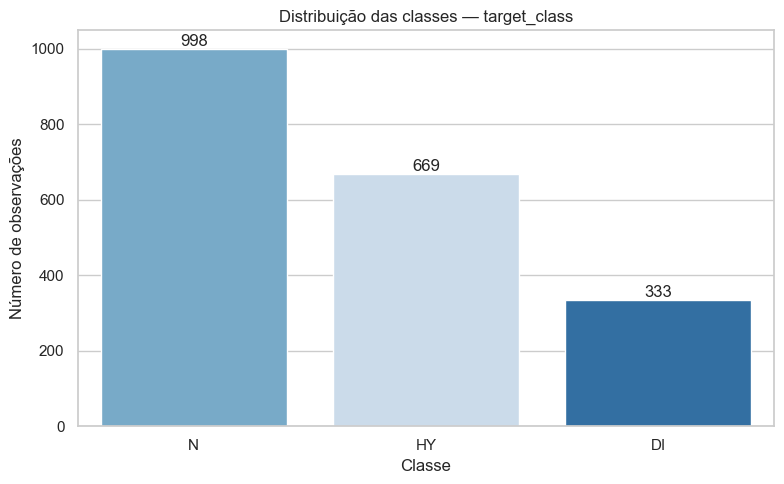

In [5]:
# ============================================================
# DISTRIBUIÇÃO DAS CLASSES
# ============================================================

class_distribution = (
    y.value_counts()
    .reindex(CLASS_LABELS, fill_value=0)
    .to_frame("Número de observações")
)

class_distribution["Percentagem (%)"] = (
    class_distribution["Número de observações"] / len(y) * 100
)

display(class_distribution.round(2))

# Representação gráfica
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=y,
    order=CLASS_LABELS,
    hue=y,
    palette="Blues",
    legend=False
)

plt.title("Distribuição das classes — target_class")
plt.xlabel("Classe")
plt.ylabel("Número de observações")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Construção das duas abordagens de preditores

In [6]:
X_42 = X_42.copy()

print("Número de features — Abordagem A:", X_42.shape[1])

# ============================================================
# FEATURES SELECIONADAS PELO LASSO
# ============================================================

selected_features = [
    "gender",
    "bmi_level",
    "age",
    "age_normalized",
    "bmi",
    "HbA1c_level",
    "cholesterol",
    "sleep_hours",
    "triglycerides",
    "physical_activity",
    "family_history",
    "stress_level",
    "low_hdl_cholesterol",
    "high_ldl_cholesterol",
    "blood_pressure",
    "sugar_consumption",
    "crp_level",
    "homocysteine_level",
    "diastolic_bp",
    "alcohol_intake",
    "salt_intake",
    "heart_rate",
    "hdl",
    "ldl",
    "plasma_value",
    "ldl_alternative",
    "age_level_Young",
    "age_level_Middle",
    "age_level_Mature",
    "age_level_Senior",
    "smoking_Never",
    "smoking_Current",
    "education_level_Primary",
    "education_level_Secondary",
    "employment_status_Unemployed",
    "employment_status_Retired"
]

# Construir o conjunto reduzido
X_36 = X_42[selected_features].copy()

print("Número de features — Abordagem B:", X_36.shape[1])

print("\nFeatures selecionadas:")
print(selected_features)

# Verificar se existem exatamente 36 features
assert X_36.shape[1] == 36, "O número de features não corresponde a 36."

# Verificar se todas as features existem
assert set(selected_features).issubset(X_42.columns)

Número de features — Abordagem A: 42
Número de features — Abordagem B: 36

Features selecionadas:
['gender', 'bmi_level', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'plasma_value', 'ldl_alternative', 'age_level_Young', 'age_level_Middle', 'age_level_Mature', 'age_level_Senior', 'smoking_Never', 'smoking_Current', 'education_level_Primary', 'education_level_Secondary', 'employment_status_Unemployed', 'employment_status_Retired']


### Separação dos dados em treino e teste
Vamos utilizar a mesma divisão do trabalho anterior:
- 80% para treino;
- 20% para teste;
- random_state=42;
- stratify=y, para preservar a proporção das classes.

In [8]:
# ============================================================
# DIVISÃO DOS DADOS
# ============================================================

# Divisão única dos índices
X_train_idx, X_test_idx, y_train, y_test = train_test_split(
    X_42.index,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Abordagem A — 42 features
X_train_42 = X_42.loc[X_train_idx]
X_test_42 = X_42.loc[X_test_idx]

# Abordagem B — 36 features
X_train_36 = X_36.loc[X_train_idx]
X_test_36 = X_36.loc[X_test_idx]

print("ABORDAGEM A — 42 FEATURES")
print("Treino:", X_train_42.shape)
print("Teste:", X_test_42.shape)

print("\nABORDAGEM B — 36 FEATURES")
print("Treino:", X_train_36.shape)
print("Teste:", X_test_36.shape)

print("\nDimensão de y_train:", y_train.shape)
print("Dimensão de y_test:", y_test.shape)

# ============================================================
# DISTRIBUIÇÃO DAS CLASSES APÓS A DIVISÃO
# ============================================================

distribution = pd.DataFrame({
    "Dataset completo": y.value_counts(normalize=True),
    "Treino": y_train.value_counts(normalize=True),
    "Teste": y_test.value_counts(normalize=True)
}).reindex(CLASS_LABELS) * 100

display(distribution.round(2))

ABORDAGEM A — 42 FEATURES
Treino: (1600, 42)
Teste: (400, 42)

ABORDAGEM B — 36 FEATURES
Treino: (1600, 36)
Teste: (400, 36)

Dimensão de y_train: (1600,)
Dimensão de y_test: (400,)


,Dataset completo,Treino,Teste
target_class,,,
N,49.90,49.88,50.0
HY,33.45,33.44,33.5
DI,16.65,16.69,16.5


### Validação cruzada estratificada
Será utilizada validação cruzada estratificada com cinco folds (StratifiedKFold).

A estratificação permite preservar aproximadamente a distribuição das classes em cada subconjunto, evitando que algumas divisões
fiquem desproporcionalmente representadas por uma determinada classe.

A validação cruzada será realizada apenas sobre os dados de treino, mantendo o conjunto de teste separado para a avaliação final.

In [9]:
# ============================================================
# CONFIGURAÇÃO DA VALIDAÇÃO CRUZADA
# ============================================================

cv_5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Métricas utilizadas na avaliação
SCORING = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

print("Validação cruzada configurada.")
print("Número de folds:", cv_5.get_n_splits())

Validação cruzada configurada.
Número de folds: 5


## Decision Trees (DT)
Nesta primeira experiência será construído um modelo Decision Tree sem otimização de hiperparâmetros.

O objetivo é estabelecer uma referência inicial para compreender o comportamento do algoritmo e permitir uma comparação posterior
com os modelos otimizados.

Serão avaliadas as duas abordagens de preditores: 42 features e 36 features.

In [10]:
# Modelo base com 42 features
dt_42 = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

# Modelo base com 36 features
dt_36 = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

# Treinar os modelos
dt_42.fit(X_train_42, y_train)
dt_36.fit(X_train_36, y_train)

print("Modelos Decision Tree treinados com sucesso.")

Modelos Decision Tree treinados com sucesso.


In [11]:
# ============================================================
# FUNÇÃO DE AVALIAÇÃO DOS MODELOS
# ============================================================

def evaluate_model(model, X, y, dataset_name, model_name):

    y_pred = model.predict(X)

    results = {
        "Modelo": model_name,
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y, y_pred),
        "Precision Macro": precision_score(
            y, y_pred, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y, y_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y, y_pred, average="macro", zero_division=0
        )
    }

    return results

In [12]:
# ============================================================
# AVALIAÇÃO NO TREINO E NO TESTE
# ============================================================

results_dt = []

# Decision Tree — 42 features
results_dt.append(
    evaluate_model(dt_42, X_train_42, y_train, "Treino", "DT - 42 features")
)

results_dt.append(
    evaluate_model(dt_42, X_test_42, y_test, "Teste", "DT - 42 features")
)

# Decision Tree — 36 features
results_dt.append(
    evaluate_model(dt_36, X_train_36, y_train, "Treino", "DT - 36 features")
)

results_dt.append(
    evaluate_model(dt_36, X_test_36, y_test, "Teste", "DT - 36 features")
)

results_dt_df = pd.DataFrame(results_dt)

display(
    results_dt_df.set_index(["Modelo", "Dataset"]).round(4)
)

Accuracy  Balanced Accuracy  Precision Macro  \
Modelo           Dataset                                                 
DT - 42 features Treino     1.0000             1.0000           1.0000   
                 Teste      0.7425             0.7780           0.7816   
DT - 36 features Treino     1.0000             1.0000           1.0000   
                 Teste      0.7775             0.8095           0.8108   

                          Recall Macro  F1 Macro  
Modelo           Dataset                          
DT - 42 features Treino         1.0000    1.0000  
                 Teste          0.7780    0.7798  
DT - 36 features Treino         1.0000    1.0000  
                 Teste          0.8095    0.8100

### Análise do overfitting

In [13]:
# ============================================================
# ANÁLISE DO OVERFITTING
# ============================================================

metrics_to_analyze = [
    "Accuracy",
    "Balanced Accuracy",
    "F1 Macro"
]

overfitting_results = []

for model_name in results_dt_df["Modelo"].unique():

    model_results = results_dt_df[
        results_dt_df["Modelo"] == model_name
    ]

    train_results = model_results[
        model_results["Dataset"] == "Treino"
    ].iloc[0]

    test_results = model_results[
        model_results["Dataset"] == "Teste"
    ].iloc[0]

    row = {"Modelo": model_name}

    for metric in metrics_to_analyze:
        row[f"Gap {metric}"] = (
            train_results[metric] - test_results[metric]
        )

    overfitting_results.append(row)

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.round(4))

,Modelo,Gap Accuracy,Gap Balanced Accuracy,Gap F1 Macro
0,DT - 42 features,0.2575,0.2220,0.2202
1,DT - 36 features,0.2225,0.1905,0.1900


### Análise à complexidade das árvores de decisão de cada modelo

In [14]:
# ============================================================
# COMPLEXIDADE DOS MODELOS
# ============================================================

tree_complexity = pd.DataFrame([
    {
        "Modelo": "DT - 42 features",
        "Profundidade": dt_42.get_depth(),
        "Número de folhas": dt_42.get_n_leaves(),
        "Número de nós": dt_42.tree_.node_count
    },
    {
        "Modelo": "DT - 36 features",
        "Profundidade": dt_36.get_depth(),
        "Número de folhas": dt_36.get_n_leaves(),
        "Número de nós": dt_36.tree_.node_count
    }
])

display(tree_complexity)

,Modelo,Profundidade,Número de folhas,Número de nós
0,DT - 42 features,20,206,411
1,DT - 36 features,19,205,409


### Avaliação através da validação cruzada estratificada

In [15]:
# ============================================================
# DECISION TREE — VALIDAÇÃO CRUZADA
# ============================================================

def cross_validate_model(model, X, y, cv, model_name):

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=SCORING,
        return_train_score=True,
        n_jobs=-1
    )

    metrics = [
        "accuracy",
        "balanced_accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ]

    results = []

    for metric in metrics:

        results.append({
            "Modelo": model_name,
            "Métrica": metric,
            "Média": scores[f"test_{metric}"].mean(),
            "Desvio-padrão": scores[f"test_{metric}"].std(),
            "Média treino": scores[f"train_{metric}"].mean()
        })

    return results


# Executar validação cruzada
cv_results_dt = []

cv_results_dt.extend(
    cross_validate_model(
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        X_train_42,
        y_train,
        cv_5,
        "DT - 42 features"
    )
)

cv_results_dt.extend(
    cross_validate_model(
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        X_train_36,
        y_train,
        cv_5,
        "DT - 36 features"
    )
)

cv_results_dt_df = pd.DataFrame(cv_results_dt)

display(
    cv_results_dt_df.round(4)
)

,Modelo,Métrica,Média,Desvio-padrão,Média treino
0,DT - 42 features,accuracy,0.7638,0.0141,1.0
1,DT - 42 features,balanced_accuracy,0.7909,0.0110,1.0
2,DT - 42 features,precision_macro,0.7939,0.0160,1.0
3,DT - 42 features,recall_macro,0.7909,0.0110,1.0
4,DT - 42 features,f1_macro,0.7918,0.0124,1.0
5,DT - 36 features,accuracy,0.7719,0.0189,1.0
6,DT - 36 features,balanced_accuracy,0.8011,0.0181,1.0
7,DT - 36 features,precision_macro,0.8037,0.0109,1.0
8,DT - 36 features,recall_macro,0.8011,0.0181,1.0
9,DT - 36 features,f1_macro,0.8018,0.0142,1.0


### Análise das previsões por classe

DECISION TREE — 42 FEATURES
              precision    recall  f1-score   support

           N       0.74      0.74      0.74       200
          HY       0.63      0.63      0.63       134
          DI       0.97      0.95      0.96        66

    accuracy                           0.74       400
   macro avg       0.78      0.78      0.78       400
weighted avg       0.74      0.74      0.74       400


DECISION TREE — 36 FEATURES
              precision    recall  f1-score   support

           N       0.78      0.77      0.77       200
          HY       0.68      0.71      0.69       134
          DI       0.97      0.95      0.96        66

    accuracy                           0.78       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.78      0.78      0.78       400



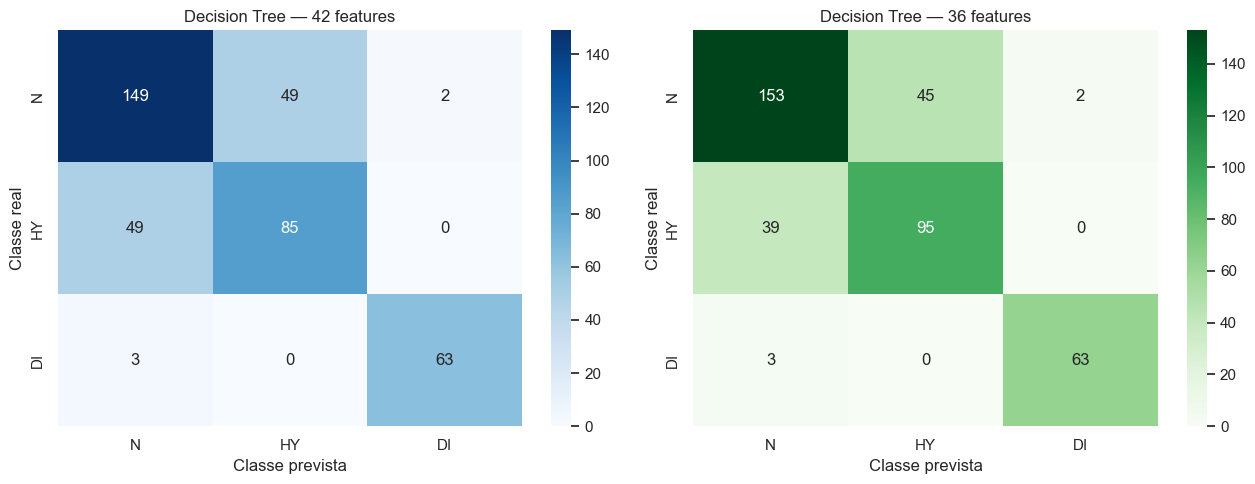

In [17]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

# Previsões no conjunto de teste
y_pred_dt_42 = dt_42.predict(X_test_42)
y_pred_dt_36 = dt_36.predict(X_test_36)

print("DECISION TREE — 42 FEATURES")
print(
    classification_report(
        y_test,
        y_pred_dt_42,
        labels=CLASS_LABELS,
        zero_division=0
    )
)

print("\nDECISION TREE — 36 FEATURES")
print(
    classification_report(
        y_test,
        y_pred_dt_36,
        labels=CLASS_LABELS,
        zero_division=0
    )
)

# ============================================================
#  MATRIZES DE CONFUSÃO
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

confusion_42 = confusion_matrix(
    y_test,
    y_pred_dt_42,
    labels=CLASS_LABELS
)

confusion_36 = confusion_matrix(
    y_test,
    y_pred_dt_36,
    labels=CLASS_LABELS
)

sns.heatmap(
    confusion_42,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_LABELS,
    yticklabels=CLASS_LABELS,
    ax=axes[0]
)

axes[0].set_title("Decision Tree — 42 features")
axes[0].set_xlabel("Classe prevista")
axes[0].set_ylabel("Classe real")

sns.heatmap(
    confusion_36,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASS_LABELS,
    yticklabels=CLASS_LABELS,
    ax=axes[1]
)

axes[1].set_title("Decision Tree — 36 features")
axes[1].set_xlabel("Classe prevista")
axes[1].set_ylabel("Classe real")

plt.tight_layout()
plt.show()

### Visualização da Decision Tree

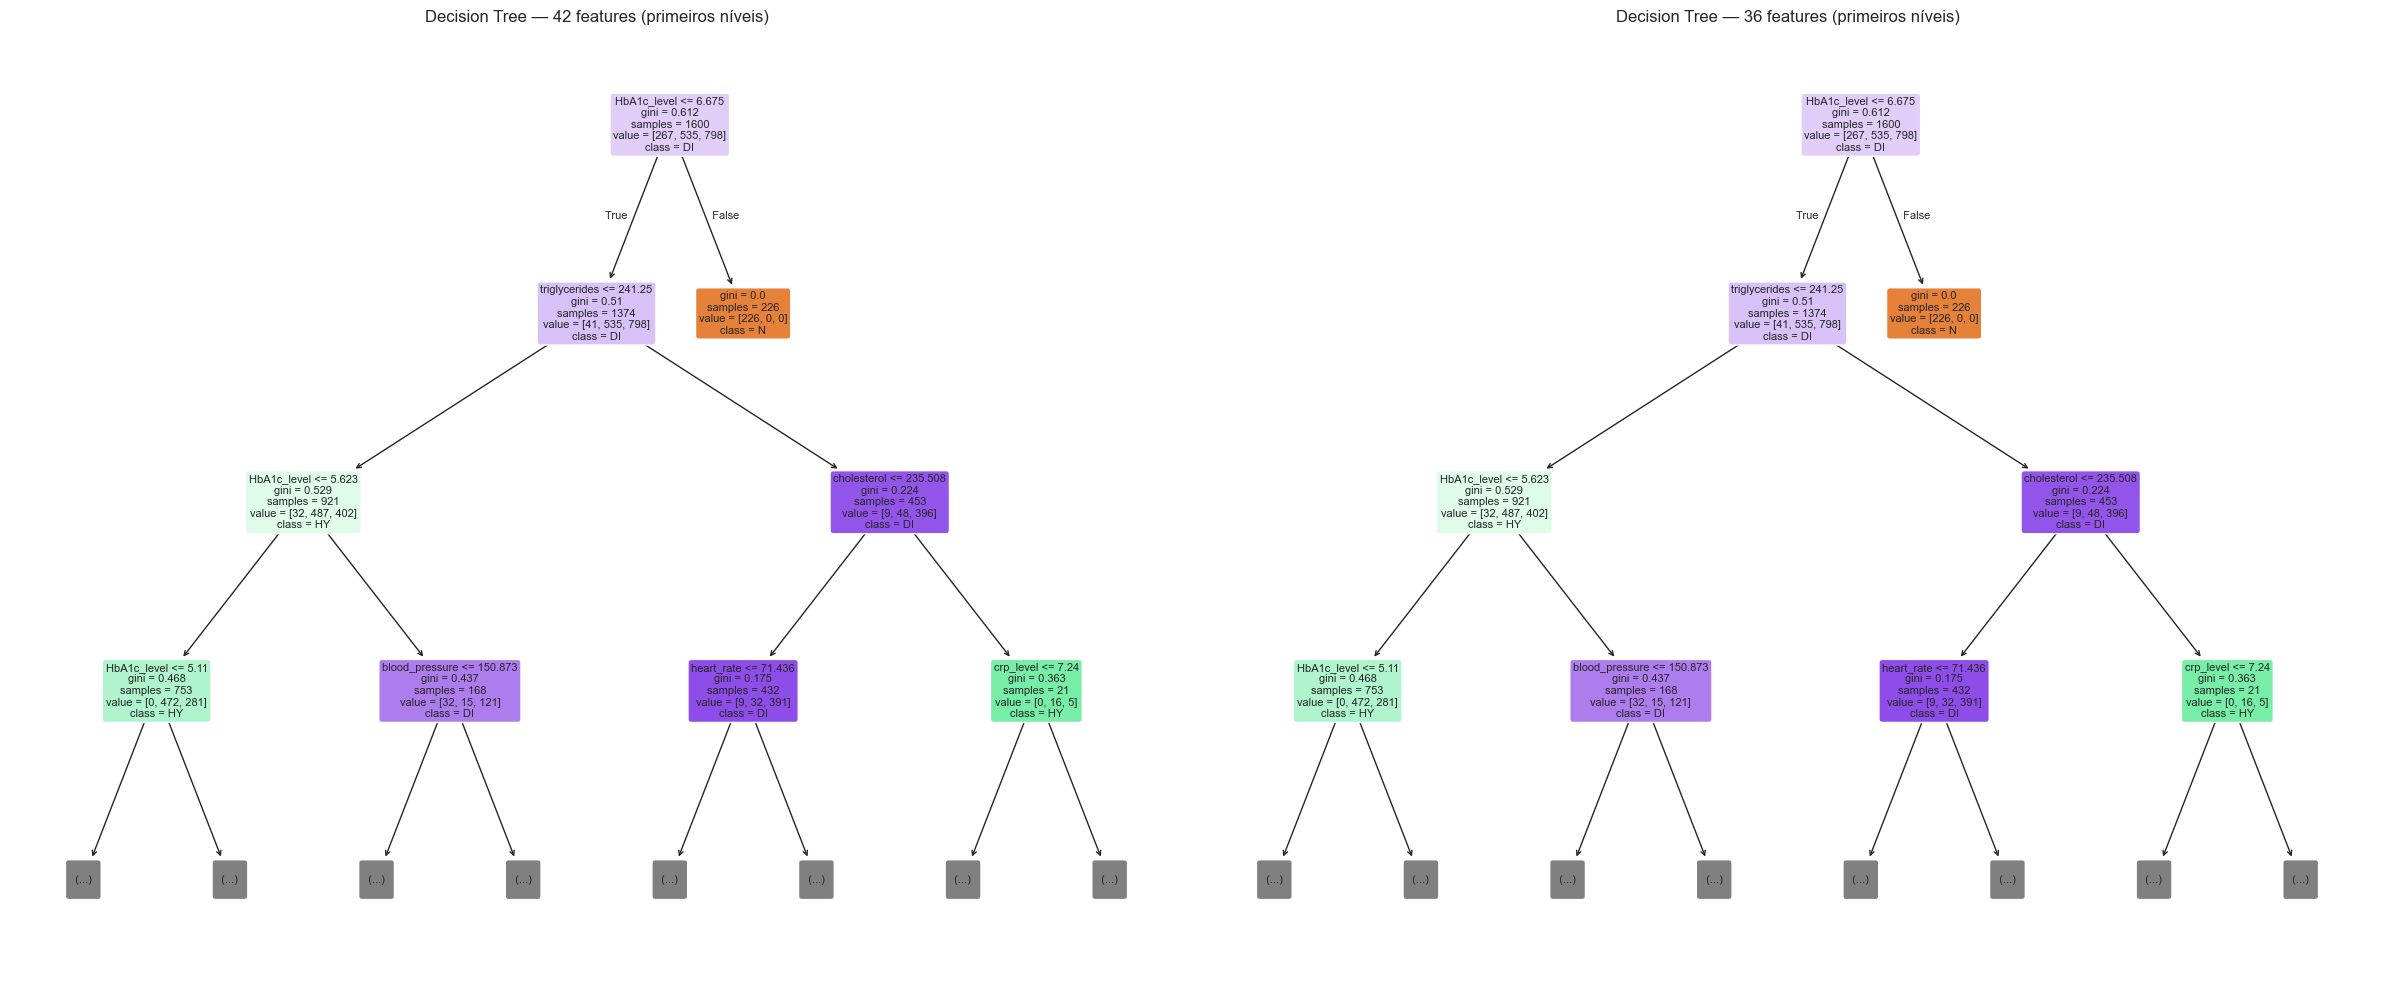

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

plot_tree(
    dt_42,
    feature_names=X_train_42.columns,
    class_names=CLASS_LABELS,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
    ax=axes[0]
)

axes[0].set_title(
    "Decision Tree — 42 features (primeiros níveis)"
)

plot_tree(
    dt_36,
    feature_names=X_train_36.columns,
    class_names=CLASS_LABELS,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
    ax=axes[1]
)

axes[1].set_title(
    "Decision Tree — 36 features (primeiros níveis)"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# REGRAS DA DECISION TREE
# ============================================================

print("REGRAS — DECISION TREE COM 42 FEATURES")

rules_42 = export_text(
    dt_42,
    feature_names=list(X_train_42.columns),
    max_depth=4
)

print(rules_42)

REGRAS — DECISION TREE COM 42 FEATURES
|--- HbA1c_level <= 6.67
|   |--- triglycerides <= 241.25
|   |   |--- HbA1c_level <= 5.62
|   |   |   |--- HbA1c_level <= 5.11
|   |   |   |   |--- alcohol_intake <= 14.86
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- alcohol_intake >  14.86
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- HbA1c_level >  5.11
|   |   |   |   |--- plasma_value <= 1.37
|   |   |   |   |   |--- truncated branch of depth 16
|   |   |   |   |--- plasma_value >  1.37
|   |   |   |   |   |--- truncated branch of depth 9
|   |   |--- HbA1c_level >  5.62
|   |   |   |--- blood_pressure <= 150.87
|   |   |   |   |--- diastolic_bp <= 83.42
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- diastolic_bp >  83.42
|   |   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- blood_pressure >  150.87
|   |   |   |   |--- class: DI
|   |--- triglycerides >  241.25
|   |   |--- cholesterol <= 235.51


In [22]:
print("\nREGRAS — DECISION TREE COM 36 FEATURES")

rules_36 = export_text(
    dt_36,
    feature_names=list(X_train_36.columns),
    max_depth=4
)

print(rules_36)


REGRAS — DECISION TREE COM 36 FEATURES
|--- HbA1c_level <= 6.67
|   |--- triglycerides <= 241.25
|   |   |--- HbA1c_level <= 5.62
|   |   |   |--- HbA1c_level <= 5.11
|   |   |   |   |--- alcohol_intake <= 14.86
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- alcohol_intake >  14.86
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- HbA1c_level >  5.11
|   |   |   |   |--- plasma_value <= 1.37
|   |   |   |   |   |--- truncated branch of depth 15
|   |   |   |   |--- plasma_value >  1.37
|   |   |   |   |   |--- truncated branch of depth 10
|   |   |--- HbA1c_level >  5.62
|   |   |   |--- blood_pressure <= 150.87
|   |   |   |   |--- diastolic_bp <= 83.42
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- diastolic_bp >  83.42
|   |   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- blood_pressure >  150.87
|   |   |   |   |--- class: DI
|   |--- triglycerides >  241.25
|   |   |--- cholesterol <= 235.5

## Intrepretação dos resultados para o modelo Decision Tree sem otimização de hiperparâmetros
Os resultados obtidos com os modelos Decision Tree mostram que a utilização das 36 features selecionadas apresenta melhores resultados do que a utilização do conjunto completo de 42 features. Esta melhoria verifica-se tanto no conjunto de teste como na validação cruzada, sendo o F1 Macro de 0.8100 no teste e 0.8018 na validação cruzada para o modelo com 36 features.

A análise por classe demonstra que a classe DI é identificada com elevada eficácia, enquanto a classe HY apresenta maiores dificuldades de classificação. Apesar da melhoria obtida com as 36 features, ambos os modelos apresentam sinais de overfitting, uma vez que atingem métricas perfeitas no treino, mas resultados inferiores nos dados não utilizados durante o ajuste.

Este comportamento poderá estar relacionado com a complexidade das árvores, que apresentam profundidades de 19 e 20 níveis. Assim, torna-se necessário otimizar os hiperparâmetros, nomeadamente a profundidade máxima, o número mínimo de amostras por divisão e o número mínimo de amostras por folha, procurando reduzir o overfitting e melhorar a capacidade de generalização.

## Decision Trees (DT): Otimização de hiperparâmetros
O objetivo é encontrar uma árvore que não memorize tão facilmente os dados de treino e que consiga manter um bom desempenho em dados novos.

In [24]:
# ============================================================
# FUNÇÃO PARA OTIMIZAÇÃO DE HIPERPARÂMETROS
# ============================================================
from sklearn.model_selection import RandomizedSearchCV

# ============================================================
# DEFINIÇÃO DO ESPAÇO DE HIPERPARÂMETROS PARA DECISION TREE
# ============================================================
param_distributions_dt = {
    "criterion": ["gini", "entropy"],

    "max_depth": [None, 3, 5, 7, 10, 15, 20],

    "min_samples_split": [2, 5, 10, 20, 30],

    "min_samples_leaf": [1, 2, 5, 10, 15],

    "ccp_alpha": [0.0, 0.0005, 0.001, 0.005, 0.01]
}

# ============================================================
# FUNÇÃO PARA OTIMIZAÇÃO DE HIPERPARÂMETROS
# ============================================================
def optimize_decision_tree(X_train, y_train, feature_set_name):

    print(f"\nOtimização da Decision Tree — {feature_set_name}")

    # Modelo inicial
    dt = DecisionTreeClassifier(random_state=RANDOM_STATE)

    # Configuração da pesquisa aleatória
    random_search = RandomizedSearchCV(
        estimator=dt,
        param_distributions=param_distributions_dt,
        n_iter=40,
        scoring="f1_macro",
        cv=cv_5,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
        refit=True,
        verbose=1
    )

    # Otimização utilizando apenas os dados de treino
    random_search.fit(X_train, y_train)

    print("\nMelhores hiperparâmetros:")
    print(random_search.best_params_)

    print("\nMelhor F1 Macro obtido na validação cruzada:")
    print(round(random_search.best_score_, 4))

    return random_search

### Otimização para os dois conjuntos de preditores: 42 features e 36 features

In [25]:
# Decision Tree — 42 features
search_dt_42 = optimize_decision_tree(
    X_train_42,
    y_train,
    "42 features"
)

# Decision Tree — 36 features
search_dt_36 = optimize_decision_tree(
    X_train_36,
    y_train,
    "36 features"
)

best_dt_42 = search_dt_42.best_estimator_

best_dt_36 = search_dt_36.best_estimator_


Otimização da Decision Tree — 42 features
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Melhores hiperparâmetros:
{'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 5, 'criterion': 'entropy', 'ccp_alpha': 0.01}

Melhor F1 Macro obtido na validação cruzada:
0.8586

Otimização da Decision Tree — 36 features
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Melhores hiperparâmetros:
{'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 5, 'criterion': 'entropy', 'ccp_alpha': 0.01}

Melhor F1 Macro obtido na validação cruzada:
0.8586


### Comparação dos melhores hiperparâmetros encontrados para cada conjunto de preditores

In [26]:
best_params_df = pd.DataFrame([
    {
        "Modelo": "DT — 42 features",
        "Melhor F1 Macro CV": search_dt_42.best_score_,
        **search_dt_42.best_params_
    },
    {
        "Modelo": "DT — 36 features",
        "Melhor F1 Macro CV": search_dt_36.best_score_,
        **search_dt_36.best_params_
    }
])

display(best_params_df.set_index("Modelo").round(4))

,Melhor F1 Macro CV,min_samples_split,min_samples_leaf,max_depth,criterion,ccp_alpha
Modelo,,,,,,
DT — 42 features,0.8586,2,2,5,entropy,0.01
DT — 36 features,0.8586,2,2,5,entropy,0.01


### Modelos Otimizados

In [27]:
results_dt_tuned = []

results_dt_tuned.append(
    evaluate_model(
        best_dt_42, X_train_42, y_train,
        "Treino", "DT Otimizada — 42 features"
    )
)

results_dt_tuned.append(
    evaluate_model(
        best_dt_42, X_test_42, y_test,
        "Teste", "DT Otimizada — 42 features"
    )
)

results_dt_tuned.append(
    evaluate_model(
        best_dt_36, X_train_36, y_train,
        "Treino", "DT Otimizada — 36 features"
    )
)

results_dt_tuned.append(
    evaluate_model(
        best_dt_36, X_test_36, y_test,
        "Teste", "DT Otimizada — 36 features"
    )
)

results_dt_tuned_df = pd.DataFrame(results_dt_tuned)

display(
    results_dt_tuned_df
    .set_index(["Modelo", "Dataset"])
    .round(4)
)

Accuracy  Balanced Accuracy  \
Modelo                     Dataset                                
DT Otimizada — 42 features Treino     0.8375             0.8641   
                           Teste      0.8400             0.8598   
DT Otimizada — 36 features Treino     0.8375             0.8641   
                           Teste      0.8400             0.8598   

                                    Precision Macro  Recall Macro  F1 Macro  
Modelo                     Dataset                                           
DT Otimizada — 42 features Treino            0.8717        0.8641    0.8605  
                           Teste             0.8699        0.8598    0.8594  
DT Otimizada — 36 features Treino            0.8717        0.8641    0.8605  
                           Teste             0.8699        0.8598    0.8594

### Complexidade das árvores de decisão dos modelos otimizados

In [28]:
tree_complexity_tuned = pd.DataFrame([
    {
        "Modelo": "DT Otimizada — 42 features",
        "Profundidade": best_dt_42.get_depth(),
        "Número de folhas": best_dt_42.get_n_leaves(),
        "Número de nós": best_dt_42.tree_.node_count
    },
    {
        "Modelo": "DT Otimizada — 36 features",
        "Profundidade": best_dt_36.get_depth(),
        "Número de folhas": best_dt_36.get_n_leaves(),
        "Número de nós": best_dt_36.tree_.node_count
    }
])

display(tree_complexity_tuned)

,Modelo,Profundidade,Número de folhas,Número de nós
0,DT Otimizada — 42 features,5,7,13
1,DT Otimizada — 36 features,5,7,13


### Comparação dos modelos otimizados com os modelos sem otimização de hiperparâmetros

In [29]:
comparison_dt = pd.concat([
    results_dt_df,
    results_dt_tuned_df
], ignore_index=True)

display(
    comparison_dt
    .pivot(
        index="Modelo",
        columns="Dataset",
        values=["Accuracy", "Balanced Accuracy", "F1 Macro"]
    )
    .round(4)
)

Accuracy         Balanced Accuracy          \
Dataset                       Teste  Treino             Teste  Treino   
Modelo                                                                  
DT - 36 features             0.7775  1.0000            0.8095  1.0000   
DT - 42 features             0.7425  1.0000            0.7780  1.0000   
DT Otimizada — 36 features   0.8400  0.8375            0.8598  0.8641   
DT Otimizada — 42 features   0.8400  0.8375            0.8598  0.8641   

                           F1 Macro          
Dataset                       Teste  Treino  
Modelo                                       
DT - 36 features             0.8100  1.0000  
DT - 42 features             0.7798  1.0000  
DT Otimizada — 36 features   0.8594  0.8605  
DT Otimizada — 42 features   0.8594  0.8605

## Intrepretação dos resultados para o modelo Decision Tree com otimização de hiperparâmetros
Após a otimização dos hiperparâmetros através do RandomizedSearchCV, verificou-se uma melhoria significativa no desempenho dos modelos Decision Tree.

O F1 Macro no conjunto de teste passou de 0.7798 para 0.8594 no modelo com 42 features e de 0.8100 para 0.8594 no modelo com 36 features.

Verificou-se também uma redução significativa da complexidade das árvores, cuja profundidade passou de 20 e 19 níveis para apenas 5 níveis, respetivamente. O número de folhas diminuiu de mais de 200 para 7 em ambos os modelos.

Esta redução da complexidade foi acompanhada por uma diminuição significativa do overfitting. Enquanto os modelos iniciais apresentavam um F1 Macro de 1.0000 no treino, os modelos otimizados apresentam valores de 0.8605 no treino e 0.8594 no teste.

Os dois conjuntos de features obtiveram exatamente os mesmos resultados após a otimização. Assim, não foi possível observar uma vantagem de desempenho na utilização de 36 em vez de 42 features nesta fase. Este resultado deverá ser analisado em conjunto com os hiperparâmetros selecionados e as previsões produzidas pelos dois modelos.

In [30]:
print("DECISION TREE — 42 FEATURES")
print(search_dt_42.best_params_)

print("\nDECISION TREE — 36 FEATURES")
print(search_dt_36.best_params_)

print("X_train_42:", X_train_42.shape)
print("X_test_42:", X_test_42.shape)

print("X_train_36:", X_train_36.shape)
print("X_test_36:", X_test_36.shape)

DECISION TREE — 42 FEATURES
{'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 5, 'criterion': 'entropy', 'ccp_alpha': 0.01}

DECISION TREE — 36 FEATURES
{'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 5, 'criterion': 'entropy', 'ccp_alpha': 0.01}
X_train_42: (1600, 42)
X_test_42: (400, 42)
X_train_36: (1600, 36)
X_test_36: (400, 36)


In [31]:
predictions_42 = best_dt_42.predict(X_test_42)
predictions_36 = best_dt_36.predict(X_test_36)

print(
    "Número de previsões iguais:",
    (predictions_42 == predictions_36).sum()
)

print(
    "Total de previsões:",
    len(y_test)
)

print(
    "As previsões são exatamente iguais?",
    np.array_equal(predictions_42, predictions_36)
)

Número de previsões iguais: 400
Total de previsões: 400
As previsões são exatamente iguais? True


In [32]:
print("F1 Macro CV — 42 features:")
print(round(search_dt_42.best_score_, 4))

print("\nF1 Macro CV — 36 features:")
print(round(search_dt_36.best_score_, 4))

F1 Macro CV — 42 features:
0.8586

F1 Macro CV — 36 features:
0.8586


### Features que contribuíram para a classificação das classes

In [33]:
from sklearn.tree import export_text

print("REGRAS — DECISION TREE 42 FEATURES")
print(export_text(
    best_dt_42,
    feature_names=list(X_train_42.columns)
))

print("\nREGRAS — DECISION TREE 36 FEATURES")
print(export_text(
    best_dt_36,
    feature_names=list(X_train_36.columns)
))

REGRAS — DECISION TREE 42 FEATURES
|--- HbA1c_level <= 6.67
|   |--- HbA1c_level <= 5.62
|   |   |--- HbA1c_level <= 5.11
|   |   |   |--- class: N
|   |   |--- HbA1c_level >  5.11
|   |   |   |--- class: HY
|   |--- HbA1c_level >  5.62
|   |   |--- triglycerides <= 138.84
|   |   |   |--- class: DI
|   |   |--- triglycerides >  138.84
|   |   |   |--- ldl <= 118.32
|   |   |   |   |--- class: DI
|   |   |   |--- ldl >  118.32
|   |   |   |   |--- age_normalized <= 0.51
|   |   |   |   |   |--- class: N
|   |   |   |   |--- age_normalized >  0.51
|   |   |   |   |   |--- class: N
|--- HbA1c_level >  6.67
|   |--- class: DI


REGRAS — DECISION TREE 36 FEATURES
|--- HbA1c_level <= 6.67
|   |--- HbA1c_level <= 5.62
|   |   |--- HbA1c_level <= 5.11
|   |   |   |--- class: N
|   |   |--- HbA1c_level >  5.11
|   |   |   |--- class: HY
|   |--- HbA1c_level >  5.62
|   |   |--- triglycerides <= 138.84
|   |   |   |--- class: DI
|   |   |--- triglycerides >  138.84
|   |   |   |--- ldl <= 118.3

### Comparação das variáveis utilizadas nos dois modelos otimizados

In [34]:
def get_used_features(model, feature_names):
    used_indices = np.unique(
        model.tree_.feature[model.tree_.feature >= 0]
    )

    return [feature_names[i] for i in used_indices]


used_features_42 = get_used_features(
    best_dt_42, list(X_train_42.columns)
)

used_features_36 = get_used_features(
    best_dt_36, list(X_train_36.columns)
)

print("Features utilizadas — 42:", used_features_42)
print("Features utilizadas — 36:", used_features_36)

Features utilizadas — 42: ['age_normalized', 'HbA1c_level', 'triglycerides', 'ldl']
Features utilizadas — 36: ['age', 'HbA1c_level', 'triglycerides', 'ldl']


### Avaliação por classe dos modelos otimizados

In [35]:
from sklearn.metrics import classification_report

y_pred_tuned_42 = best_dt_42.predict(X_test_42)
y_pred_tuned_36 = best_dt_36.predict(X_test_36)

print("DECISION TREE OTIMIZADA — 42 FEATURES")
print(classification_report(
    y_test,
    y_pred_tuned_42,
    labels=CLASS_LABELS,
    zero_division=0
))

print("\nDECISION TREE OTIMIZADA — 36 FEATURES")
print(classification_report(
    y_test,
    y_pred_tuned_36,
    labels=CLASS_LABELS,
    zero_division=0
))

DECISION TREE OTIMIZADA — 42 FEATURES
              precision    recall  f1-score   support

           N       0.90      0.78      0.83       200
          HY       0.73      0.91      0.81       134
          DI       0.98      0.89      0.94        66

    accuracy                           0.84       400
   macro avg       0.87      0.86      0.86       400
weighted avg       0.85      0.84      0.84       400


DECISION TREE OTIMIZADA — 36 FEATURES
              precision    recall  f1-score   support

           N       0.90      0.78      0.83       200
          HY       0.73      0.91      0.81       134
          DI       0.98      0.89      0.94        66

    accuracy                           0.84       400
   macro avg       0.87      0.86      0.86       400
weighted avg       0.85      0.84      0.84       400



## Conclusão final 
A otimização dos hiperparâmetros permitiu melhorar significativamente o desempenho dos modelos Decision Tree, tendo o F1 Macro no conjunto de teste aumentado para 0.8594. Simultaneamente, verificou-se uma redução da profundidade das árvores de 19–20 para 5 níveis e uma diminuição do número de folhas de mais de 200 para apenas 7.

Os dois conjuntos de features selecionaram exatamente os mesmos hiperparâmetros: criterion='entropy', max_depth=5, min_samples_split=2, min_samples_leaf=2 e ccp_alpha=0.01. Além disso, produziram as mesmas previsões nos 400 registos de teste e obtiveram um F1 Macro de 0.8586 na validação cruzada.

Estes resultados indicam que, após a otimização, a utilização das 36 features não proporcionou uma vantagem adicional relativamente às 42 features. A redução da complexidade da árvore contribuiu para diminuir o overfitting e melhorar a capacidade de generalização.

## Random Forest (RF)
Nesta primeira experiência será construído um modelo Random Forest sem otimização de hiperparâmetros.

O objetivo é estabelecer uma referência inicial para compreender o comportamento do algoritmo e permitir uma comparação posterior
com os modelos otimizados.

Serão avaliadas as duas abordagens de preditores: 42 features e 36 features.

In [36]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np

rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

### Treinamento do modelo Random Forest sem otimização de hiperparâmetros

In [45]:
rf_model.fit(X_train_42, y_train)

# Previsões
y_train_pred_42 = rf_model.predict(X_train_42)
y_test_pred_42 = rf_model.predict(X_test_42)

print("RANDOM FOREST — 42 FEATURES")

# Métricas de treino
print("TRAIN RESULTS")

print("Accuracy:",
      accuracy_score(y_train, y_train_pred_42))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_train, y_train_pred_42))

print("Precision Macro:",
      precision_score(y_train, y_train_pred_42,
                      average="macro", zero_division=0))

print("Recall Macro:",
      recall_score(y_train, y_train_pred_42,
                   average="macro", zero_division=0))

print("F1 Macro:",
      f1_score(y_train, y_train_pred_42,
               average="macro", zero_division=0))


# Métricas de teste
print("\nTEST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_test_pred_42))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_test_pred_42))

print("Precision Macro:",
      precision_score(y_test, y_test_pred_42,
                      average="macro", zero_division=0))

print("Recall Macro:",
      recall_score(y_test, y_test_pred_42,
                   average="macro", zero_division=0))

print("F1 Macro:",
      f1_score(y_test, y_test_pred_42,
               average="macro", zero_division=0))

RANDOM FOREST — 42 FEATURES
TRAIN RESULTS
Accuracy: 1.0
Balanced Accuracy: 1.0
Precision Macro: 1.0
Recall Macro: 1.0
F1 Macro: 1.0

TEST RESULTS
Accuracy: 0.8375
Balanced Accuracy: 0.8674596713402684
Precision Macro: 0.8717948717948718
Recall Macro: 0.8674596713402684
F1 Macro: 0.8637593688230613


In [46]:
rf_model.fit(X_train_36, y_train)

# Previsões
y_train_pred_36 = rf_model.predict(X_train_36)
y_test_pred_36 = rf_model.predict(X_test_36)

print("RANDOM FOREST — 36 FEATURES")

# Métricas de treino
print("TRAIN RESULTS")

print("Accuracy:",
      accuracy_score(y_train, y_train_pred_36))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_train, y_train_pred_36))

print("Precision Macro:",
      precision_score(y_train, y_train_pred_36,
                      average="macro", zero_division=0))

print("Recall Macro:",
      recall_score(y_train, y_train_pred_36,
                   average="macro", zero_division=0))

print("F1 Macro:",
      f1_score(y_train, y_train_pred_36,
               average="macro", zero_division=0))


# Métricas de teste
print("\nTEST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_test_pred_36))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_test_pred_36))

print("Precision Macro:",
      precision_score(y_test, y_test_pred_36,
                      average="macro", zero_division=0))

print("Recall Macro:",
      recall_score(y_test, y_test_pred_36,
                   average="macro", zero_division=0))

print("F1 Macro:",
      f1_score(y_test, y_test_pred_36,
               average="macro", zero_division=0))

RANDOM FOREST — 36 FEATURES
TRAIN RESULTS
Accuracy: 1.0
Balanced Accuracy: 1.0
Precision Macro: 1.0
Recall Macro: 1.0
F1 Macro: 1.0

TEST RESULTS
Accuracy: 0.835
Balanced Accuracy: 0.8649721091512136
Precision Macro: 0.869467787114846
Recall Macro: 0.8649721091512136
F1 Macro: 0.8616912027921962


### Matriz de confusão do modelo Random Forest sem otimização de hiperparâmetros

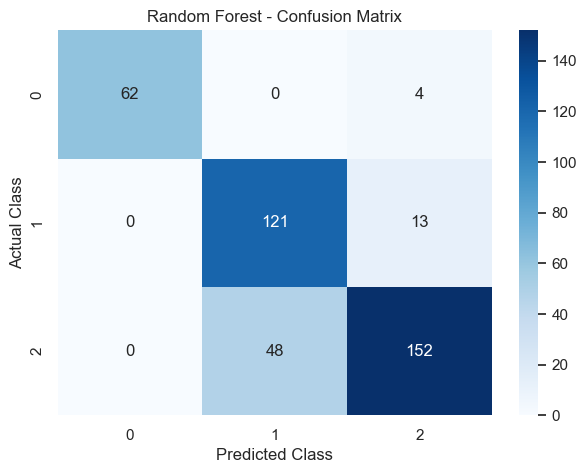

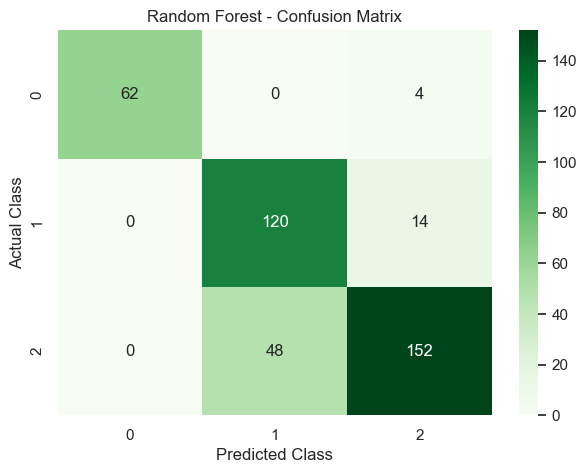

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_test_pred_42)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")

plt.show()

cm = confusion_matrix(y_test, y_test_pred_36)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [50]:
print("Random Forest - 42 Features")
print(classification_report(
    y_test,
    y_test_pred_42,
    zero_division=0
))

print("\nRandom Forest - 36 Features")
print(classification_report(
    y_test,
    y_test_pred_36,
    zero_division=0
))

Random Forest - 42 Features
              precision    recall  f1-score   support

          DI       1.00      0.94      0.97        66
          HY       0.72      0.90      0.80       134
           N       0.90      0.76      0.82       200

    accuracy                           0.84       400
   macro avg       0.87      0.87      0.86       400
weighted avg       0.85      0.84      0.84       400


Random Forest - 36 Features
              precision    recall  f1-score   support

          DI       1.00      0.94      0.97        66
          HY       0.71      0.90      0.79       134
           N       0.89      0.76      0.82       200

    accuracy                           0.83       400
   macro avg       0.87      0.86      0.86       400
weighted avg       0.85      0.83      0.84       400

